# Entrenamiento del modelo

Entrena y evalúa el clasificador con las carpetas de `data/processed/` generadas por `data_setup.ipynb`. Cada versión agrega un cambio sobre una anterior; el análisis de los resultados está en el reporte.

| Versión | Cambio |
|---|---|
| v1 | CNN pequeña entrenada desde cero |
| v2 | v1 + aumento de datos + Dropout |
| v3 | Transfer learning con EfficientNetB0 congelada |
| v4 | v3 + fine-tuning del último bloque |
| v5 | Multi-recorte a 384 px con EfficientNetB0 como extractor de características |
| v6 | v5 reentrenada con train + val |
| v7 | v5 entrenada y evaluada en escala de grises |
| v8 | v5 con imágenes a color (peso 0.5) y en grises, evaluada en grises |
| v9 | v7 reentrenada con train + val (**modelo final**) |

Métricas: accuracy, top-5 accuracy y F1 macro. Las decisiones se toman con `val`; `test` solo se reporta. La v6 y la v9 se entrenan con `val`, así que solo tienen métricas de `test`.

In [1]:
import json
import time
from pathlib import Path

import keras
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from keras import layers
from PIL import Image
from sklearn.metrics import classification_report, confusion_matrix, f1_score

ROOT = Path("..")   # los notebooks se corren desde notebooks/

DATA_DIR = ROOT / "data" / "processed"
MODELS_DIR = ROOT / "models"
VERSIONS_DIR = MODELS_DIR / "versions"
FIGURES_DIR = ROOT / "docs" / "figures"
for d in (MODELS_DIR, VERSIONS_DIR, FIGURES_DIR):
    d.mkdir(parents=True, exist_ok=True)

SEED = 42
IMG_SIZE = 224
BATCH_SIZE = 32
RESIZE_HEIGHT = 384   # debe coincidir con el de data_setup (src/app.py lo replica)

keras.utils.set_random_seed(SEED)
print("TensorFlow", tf.__version__, "| Keras", keras.__version__)
print("Dispositivos:", [d.device_type for d in tf.config.list_physical_devices()])

def savefig(name):
    # guarda cada figura también en docs/figures para usarla en el reporte
    plt.savefig(FIGURES_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

TensorFlow 2.21.0 | Keras 3.15.1
Dispositivos: ['CPU']


## 1. Carga de datos

Los nombres de clase se toman de `train` y se fuerzan en `val` y `test` para que los índices coincidan. Las versiones v1–v4 estiran las splash (≈651×384) a 224×224 al cargarlas; v5–v9 las usan completas.

In [2]:
CLASS_NAMES = sorted(p.name for p in (DATA_DIR / "train").iterdir() if p.is_dir())
NUM_CLASSES = len(CLASS_NAMES)

def load_split(split, size=(IMG_SIZE, IMG_SIZE), shuffle=False):
    ds = keras.utils.image_dataset_from_directory(
        DATA_DIR / split,
        class_names=CLASS_NAMES,
        label_mode="int",
        image_size=size,
        batch_size=BATCH_SIZE,
        shuffle=shuffle,
        seed=SEED,
        verbose=False,
    )
    return ds.cache().prefetch(tf.data.AUTOTUNE)

def labels_of(ds):
    return np.concatenate([y.numpy() for _, y in ds])

train_ds = load_split("train", shuffle=True)
val_ds = load_split("val")
test_ds = load_split("test")
# Si hay archivos que no están en el manifest (por ejemplo copias "foto 2.jpg" de iCloud), detenerse
expected = pd.read_csv(DATA_DIR / "manifest.csv").split.value_counts()
for name, ds in [("train", train_ds), ("val", val_ds), ("test", test_ds)]:
    n = len(labels_of(ds))
    assert n == expected[name], f"{name}: {n} imágenes en disco, {expected[name]} en manifest.csv"
    print(f"{name}: {n} imágenes")
print("Clases:", NUM_CLASSES, "| azar:", f"{1 / NUM_CLASSES:.3f}")

train: 916 imágenes
val: 95 imágenes
test: 95 imágenes
Clases: 38 | azar: 0.026


## 2. Funciones de entrenamiento y evaluación

- `fit`: Adam + `sparse_categorical_crossentropy`. `ValF1` calcula el F1 macro de `val` al final de cada época y lo agrega a los logs como `val_f1`, que usan `EarlyStopping` y `ReduceLROnPlateau`.
- `evaluate`: guarda la versión en `models/versions/` y agrega sus métricas a `results`.

In [3]:
class ValF1(keras.callbacks.Callback):
    # Calcula el F1 macro de validación al final de cada época y lo agrega a los logs.
    def __init__(self, val):
        super().__init__()
        self.val = val
        self.y_val = labels_of(val)

    def on_epoch_end(self, epoch, logs=None):
        pred = self.model.predict(self.val, verbose=0).argmax(axis=1)
        logs["val_f1"] = f1_score(self.y_val, pred, average="macro", zero_division=0)


results = []
input_sizes = {}   # versión -> (alto, ancho) de su entrada
grayscale = set()  # versiones que reciben la imagen en escala de grises

def compile_model(model, lr):
    model.compile(
        optimizer=keras.optimizers.Adam(lr),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy", keras.metrics.SparseTopKCategoricalAccuracy(k=5, name="top5")],
    )

def fit(model, name, train, val, epochs, lr, patience=10, initial_epoch=0):
    compile_model(model, lr)
    callbacks = [
        ValF1(val),   # va primero: los siguientes leen val_f1
        keras.callbacks.EarlyStopping(monitor="val_f1", mode="max", patience=patience,
                                      restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_f1", mode="max", factor=0.5,
                                          patience=max(2, patience // 3), min_lr=1e-7),
    ]
    start = time.time()
    hist = model.fit(train, validation_data=val, epochs=epochs,
                     initial_epoch=initial_epoch, callbacks=callbacks, verbose=2)
    best = int(np.argmax(hist.history["val_f1"]))
    print(f"{name}: {time.time() - start:.0f} s | mejor época {initial_epoch + best + 1} "
          f"(val_f1 {hist.history['val_f1'][best]:.3f})")
    return hist

def scores(model, ds):
    y = labels_of(ds)
    probs = model.predict(ds, verbose=0)
    top5 = np.argsort(probs, axis=1)[:, -5:]
    return {
        "acc": float((probs.argmax(1) == y).mean()),
        "top5": float(np.mean([t in row for t, row in zip(y, top5)])),
        "f1": f1_score(y, probs.argmax(1), average="macro", zero_division=0),
    }

def evaluate(model, name, description, hist, val, test, size=(IMG_SIZE, IMG_SIZE), gray=False):
    model.save(VERSIONS_DIR / f"{name}.keras")   # copia de cada versión tal como se evaluó
    input_sizes[name] = size
    if gray:
        grayscale.add(name)
    v, t = scores(model, val), scores(model, test)
    best = int(np.argmax(hist.history["val_f1"]))
    row = {
        "versión": name, "cambio": description, "entrada": f"{size[1]}x{size[0]}" + (" grises" if gray else ""),
        "épocas": len(hist.history["loss"]),
        "train acc": hist.history["accuracy"][best],   # en la época restaurada
        "val acc": v["acc"], "val top5": v["top5"], "val f1": v["f1"],
        "test acc": t["acc"], "test top5": t["top5"], "test f1": t["f1"],
    }
    results.append(row)
    return pd.DataFrame([row]).set_index("versión").round(3)

def plot_history(hist, title):
    fig, (a1, a2, a3) = plt.subplots(1, 3, figsize=(15, 3.5))
    a1.plot(hist.history["loss"], label="train"); a1.plot(hist.history["val_loss"], label="val")
    a2.plot(hist.history["accuracy"], label="train"); a2.plot(hist.history["val_accuracy"], label="val")
    a3.plot(hist.history["val_f1"], label="val", color="tab:orange")
    best = int(np.argmax(hist.history["val_f1"]))
    for a, metric in [(a1, "loss"), (a2, "accuracy"), (a3, "F1 macro")]:
        a.axvline(best, color="gray", ls="--", lw=1)
        a.set_title(f"{title} - {metric}"); a.set_xlabel("época"); a.legend()
    savefig(f"curvas_{title}")
    plt.show()

## 3. v1: CNN desde cero

Tres bloques `Conv2D` + `MaxPooling2D` y un clasificador denso con softmax.

In [4]:
def build_cnn(augment=None, dropout=0.0):
    inputs = keras.Input((IMG_SIZE, IMG_SIZE, 3))
    x = augment(inputs) if augment else inputs
    x = layers.Rescaling(1 / 255)(x)
    for filters in [32, 64, 128]:
        x = layers.Conv2D(filters, 3, activation="relu")(x)
        x = layers.MaxPooling2D()(x)
    x = layers.Flatten()(x)
    if dropout:
        x = layers.Dropout(dropout)(x)
    x = layers.Dense(256, activation="relu")(x)
    if dropout:
        x = layers.Dropout(dropout)(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)
    return keras.Model(inputs, outputs)

v1 = build_cnn()
v1.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │    22,151,424 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 38)             │         9,766 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 22,254,438 (84.89 MB)

 Trainable params: 22,254,438 (84.89 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30


/Users/emiliolopez/Desktop/Septimo Semestre/lol-champion-classifier.nosync/.venv/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


29/29 - 10s - 351ms/step - accuracy: 0.0338 - loss: 3.6839 - top5: 0.1430 - val_accuracy: 0.0211 - val_loss: 3.6373 - val_top5: 0.1368 - val_f1: 0.0034 - learning_rate: 0.0010


Epoch 2/30


29/29 - 9s - 319ms/step - accuracy: 0.0459 - loss: 3.6219 - top5: 0.1910 - val_accuracy: 0.0316 - val_loss: 3.6459 - val_top5: 0.1474 - val_f1: 0.0016 - learning_rate: 0.0010


Epoch 3/30


... (28 outputs left out)

29/29 - 9s - 320ms/step - accuracy: 1.0000 - loss: 2.8582e-05 - top5: 1.0000 - val_accuracy: 0.0947 - val_loss: 7.9707 - val_top5: 0.2737 - val_f1: 0.0867 - learning_rate: 2.5000e-04


Epoch 18/30


29/29 - 9s - 323ms/step - accuracy: 1.0000 - loss: 2.7621e-05 - top5: 1.0000 - val_accuracy: 0.0947 - val_loss: 7.9815 - val_top5: 0.2737 - val_f1: 0.0867 - learning_rate: 1.2500e-04


v1: 180 s | mejor época 8 (val_f1 0.099)


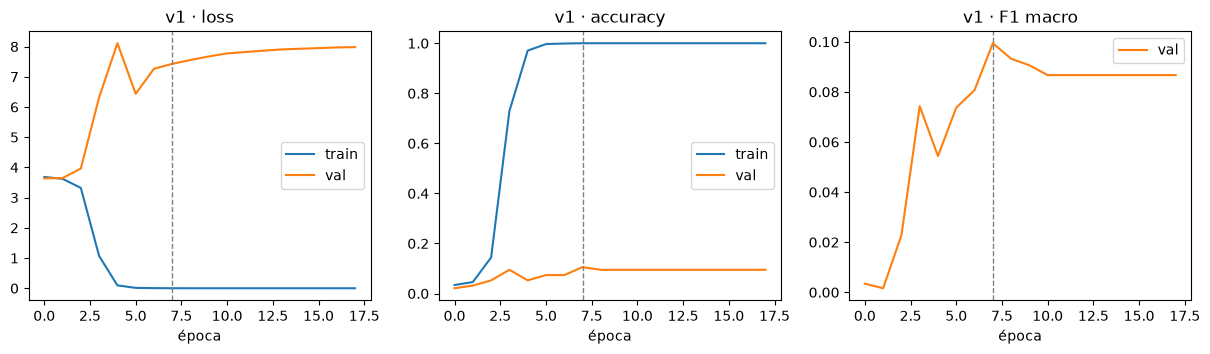

,cambio,entrada,épocas,train acc,val acc,val top5,val f1,test acc,test top5,test f1
versión,,,,,,,,,,
v1,CNN desde cero,224×224,18,1.0,0.105,0.284,0.099,0.105,0.305,0.105


In [5]:
h1 = fit(v1, "v1", train_ds, val_ds, epochs=30, lr=1e-3)
plot_history(h1, "v1")
evaluate(v1, "v1", "CNN desde cero", h1, val_ds, test_ds)

## 4. v2: Aumento de datos + Dropout

Las capas de aumento solo actúan durante el entrenamiento; en `val`/`test` no modifican la imagen.

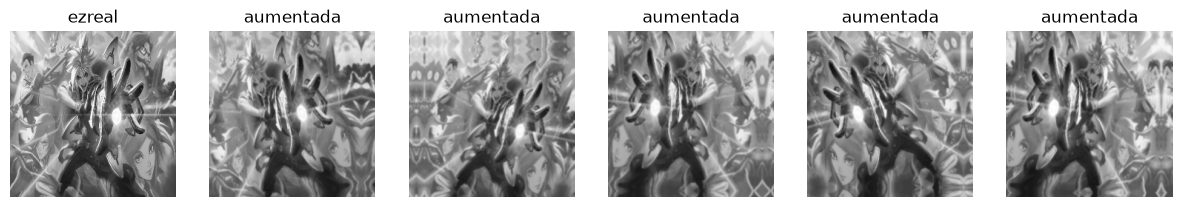

In [6]:
augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.15),
    layers.RandomTranslation(0.1, 0.1),
    layers.RandomContrast(0.2),
], name="augmentation")

# Ejemplos de aumento sobre una imagen de train
images, labels = next(iter(train_ds))
fig, axes = plt.subplots(1, 6, figsize=(15, 2.6))
axes[0].imshow(images[0].numpy().astype("uint8")); axes[0].set_title(CLASS_NAMES[labels[0]])
for ax in axes[1:]:
    ax.imshow(np.clip(augmentation(images[:1], training=True)[0].numpy(), 0, 255).astype("uint8"))
    ax.set_title("aumentada")
for ax in axes:
    ax.axis("off")
savefig("aumento_de_datos")
plt.show()

Epoch 1/60


/Users/emiliolopez/Desktop/Septimo Semestre/lol-champion-classifier.nosync/.venv/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


29/29 - 11s - 390ms/step - accuracy: 0.0240 - loss: 3.7853 - top5: 0.1408 - val_accuracy: 0.0316 - val_loss: 3.6373 - val_top5: 0.1474 - val_f1: 0.0043 - learning_rate: 0.0010


Epoch 2/60


29/29 - 10s - 351ms/step - accuracy: 0.0186 - loss: 3.6402 - top5: 0.1365 - val_accuracy: 0.0105 - val_loss: 3.6368 - val_top5: 0.1474 - val_f1: 5.7837e-04 - learning_rate: 0.0010


Epoch 3/60


... (44 outputs left out)

29/29 - 10s - 350ms/step - accuracy: 0.1212 - loss: 3.2590 - top5: 0.3734 - val_accuracy: 0.0211 - val_loss: 3.7171 - val_top5: 0.1789 - val_f1: 0.0123 - learning_rate: 1.2500e-04


Epoch 26/60


29/29 - 10s - 354ms/step - accuracy: 0.1354 - loss: 3.2003 - top5: 0.4138 - val_accuracy: 0.0211 - val_loss: 3.7401 - val_top5: 0.1789 - val_f1: 0.0123 - learning_rate: 1.2500e-04


v2: 268 s | mejor época 11 (val_f1 0.032)


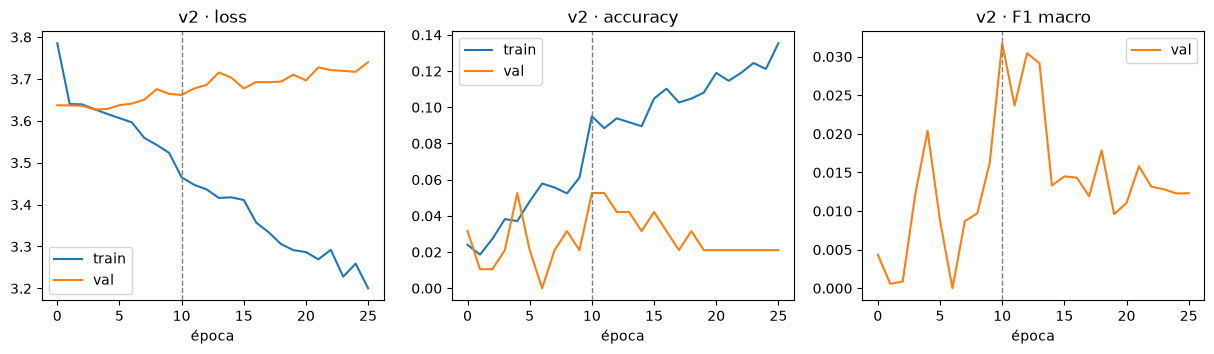

,cambio,entrada,épocas,train acc,val acc,val top5,val f1,test acc,test top5,test f1
versión,,,,,,,,,,
v2,v1 + aumento de datos + Dropout,224×224,26,0.095,0.053,0.168,0.032,0.063,0.189,0.036


In [7]:
v2 = build_cnn(augment=augmentation, dropout=0.5)
h2 = fit(v2, "v2", train_ds, val_ds, epochs=60, lr=1e-3, patience=15)
plot_history(h2, "v2")
evaluate(v2, "v2", "v1 + aumento de datos + Dropout", h2, val_ds, test_ds)

## 5. v3: Transfer learning con EfficientNetB0

- `include_top=False` quita el clasificador de ImageNet y `base.trainable = False` congela la base.
- EfficientNet incluye su propia normalización, así que recibe pixeles en [0, 255] sin `Rescaling`.

In [8]:
def build_transfer(dropout=0.3):
    base = keras.applications.EfficientNetB0(input_shape=(IMG_SIZE, IMG_SIZE, 3),
                                             include_top=False, weights="imagenet")
    base.trainable = False

    inputs = keras.Input((IMG_SIZE, IMG_SIZE, 3))
    x = augmentation(inputs)
    x = base(x, training=False)   # BatchNorm de la base siempre en modo inferencia
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(dropout)(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)
    return keras.Model(inputs, outputs), base

def count_params(model):
    trainable = sum(np.prod(w.shape) for w in model.trainable_weights)
    frozen = sum(np.prod(w.shape) for w in model.non_trainable_weights)
    print(f"Parámetros entrenables: {trainable:,} | congelados: {frozen:,}")

v3, base3 = build_transfer()
count_params(v3)

Parámetros entrenables: 48,678 | congelados: 4,049,571.0


Epoch 1/50


/Users/emiliolopez/Desktop/Septimo Semestre/lol-champion-classifier.nosync/.venv/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


29/29 - 15s - 522ms/step - accuracy: 0.0480 - loss: 3.7205 - top5: 0.1670 - val_accuracy: 0.0526 - val_loss: 3.5431 - val_top5: 0.2526 - val_f1: 0.0369 - learning_rate: 0.0010


Epoch 2/50


29/29 - 7s - 238ms/step - accuracy: 0.1070 - loss: 3.3890 - top5: 0.3286 - val_accuracy: 0.0842 - val_loss: 3.4194 - val_top5: 0.3368 - val_f1: 0.0691 - learning_rate: 0.0010


Epoch 3/50


... (58 outputs left out)

29/29 - 7s - 241ms/step - accuracy: 0.6321 - loss: 1.6268 - top5: 0.9007 - val_accuracy: 0.1789 - val_loss: 3.2451 - val_top5: 0.3684 - val_f1: 0.1643 - learning_rate: 3.1250e-05


Epoch 33/50


29/29 - 7s - 233ms/step - accuracy: 0.6528 - loss: 1.6175 - top5: 0.9072 - val_accuracy: 0.1789 - val_loss: 3.2455 - val_top5: 0.3684 - val_f1: 0.1643 - learning_rate: 1.5625e-05


v3: 241 s | mejor época 23 (val_f1 0.165)


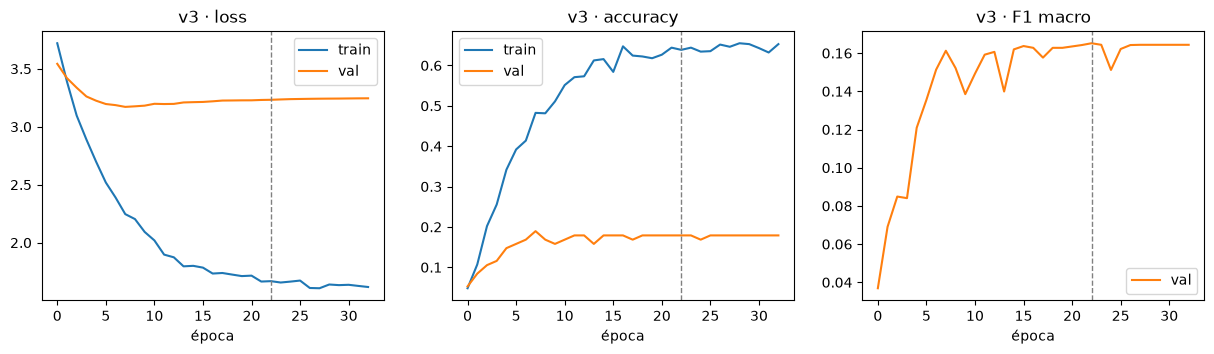

,cambio,entrada,épocas,train acc,val acc,val top5,val f1,test acc,test top5,test f1
versión,,,,,,,,,,
v3,EfficientNetB0 congelada + aumento,224×224,33,0.639,0.179,0.368,0.165,0.126,0.421,0.108


In [9]:
h3 = fit(v3, "v3", train_ds, val_ds, epochs=50, lr=1e-3)
plot_history(h3, "v3")
evaluate(v3, "v3", "EfficientNetB0 congelada + aumento", h3, val_ds, test_ds)

## 6. v4: Fine-tuning

Se parte de los pesos de v3, se descongela desde `block6a` y se entrena con learning rate 1e-5. Las capas `BatchNormalization` se mantienen congeladas.

Capas descongeladas: 59 de 238
Parámetros entrenables: 3,178,562 | congelados: 919,687.0
Epoch 34/73


/Users/emiliolopez/Desktop/Septimo Semestre/lol-champion-classifier.nosync/.venv/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


29/29 - 18s - 632ms/step - accuracy: 0.6343 - loss: 1.6045 - top5: 0.8897 - val_accuracy: 0.1789 - val_loss: 3.3204 - val_top5: 0.3684 - val_f1: 0.1525 - learning_rate: 1.0000e-05


Epoch 35/73


29/29 - 9s - 310ms/step - accuracy: 0.6474 - loss: 1.5031 - top5: 0.9050 - val_accuracy: 0.1895 - val_loss: 3.3783 - val_top5: 0.3579 - val_f1: 0.1571 - learning_rate: 1.0000e-05


Epoch 36/73


... (20 outputs left out)

29/29 - 9s - 309ms/step - accuracy: 0.6823 - loss: 1.1927 - top5: 0.9356 - val_accuracy: 0.1789 - val_loss: 3.5412 - val_top5: 0.3789 - val_f1: 0.1506 - learning_rate: 2.5000e-06


Epoch 47/73


29/29 - 9s - 304ms/step - accuracy: 0.7074 - loss: 1.1326 - top5: 0.9378 - val_accuracy: 0.1684 - val_loss: 3.5449 - val_top5: 0.3789 - val_f1: 0.1448 - learning_rate: 1.2500e-06


v4: 134 s | mejor época 37 (val_f1 0.173)


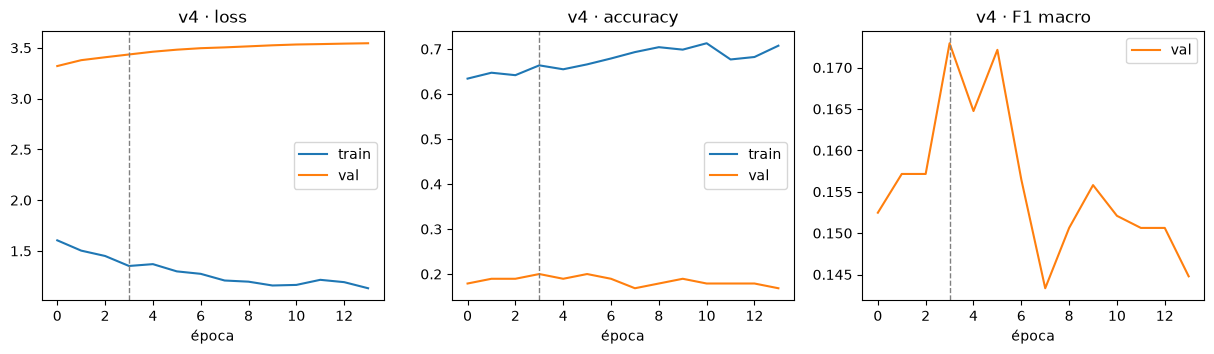

,cambio,entrada,épocas,train acc,val acc,val top5,val f1,test acc,test top5,test f1
versión,,,,,,,,,,
v4,v3 + fine-tuning desde block6a,224×224,14,0.664,0.2,0.337,0.173,0.126,0.411,0.098


In [10]:
v4, base4 = v3, base3   # se continúa desde v3 (ya guardada en models/versions/v3.keras)

first = next(i for i, l in enumerate(base4.layers) if l.name.startswith("block6a"))
base4.trainable = True
for i, layer in enumerate(base4.layers):
    layer.trainable = i >= first and not isinstance(layer, layers.BatchNormalization)
print(f"Capas descongeladas: {sum(l.trainable for l in base4.layers)} de {len(base4.layers)}")
count_params(v4)

start_epoch = len(h3.history["loss"])
h4 = fit(v4, "v4", train_ds, val_ds, epochs=start_epoch + 40, lr=1e-5, initial_epoch=start_epoch)
plot_history(h4, "v4")
evaluate(v4, "v4", "v3 + fine-tuning desde block6a", h4, val_ds, test_ds)

## 7. v5: Multi-recorte a 384 px

La splash de 651×384 se divide en tres recortes de 384×384 (izquierda, centro y derecha) que pasan por la misma EfficientNetB0; sus características se concatenan.

Como la base está congelada, las características se calculan una sola vez y solo se entrena el clasificador sobre ellas. Por eso no hay aumento aleatorio: se agrega una copia volteada de cada imagen de `train`. Al final, extractor y clasificador se unen en un solo modelo que recibe la splash completa.

Entrada: 651×384 → 3 recortes de 384×384 → 3840 características


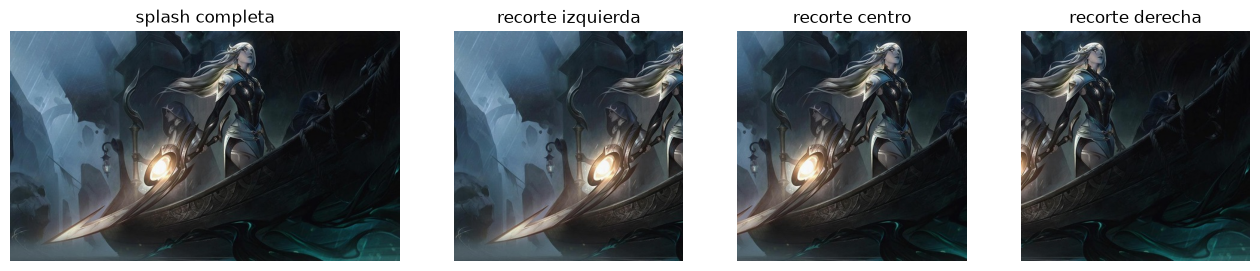

In [11]:
V5_HEIGHT = RESIZE_HEIGHT
V5_WIDTH = Image.open(next((DATA_DIR / "train").rglob("*.jpg"))).size[0]   # ancho de las splash guardadas
V5_SIZE = (V5_HEIGHT, V5_WIDTH)

def build_multicrop_extractor():
    base = keras.applications.EfficientNetB0(input_shape=(V5_HEIGHT, V5_HEIGHT, 3), include_top=False,
                                             weights="imagenet", pooling="avg")
    base.trainable = False

    inputs = keras.Input((V5_HEIGHT, V5_WIDTH, 3))
    extra = V5_WIDTH - V5_HEIGHT   # pixeles que sobran a lo ancho para un cuadrado
    crops = [
        layers.Cropping2D(((0, 0), (0, extra)), name="recorte_izquierda")(inputs),
        layers.Cropping2D(((0, 0), (extra // 2, extra - extra // 2)), name="recorte_centro")(inputs),
        layers.Cropping2D(((0, 0), (extra, 0)), name="recorte_derecha")(inputs),
    ]
    features = [base(c, training=False) for c in crops]   # misma red y mismos pesos para los tres
    return keras.Model(inputs, layers.Concatenate(name="caracteristicas")(features),
                       name="extractor_multirecorte")

extractor = build_multicrop_extractor()
print(f"Entrada: {V5_WIDTH}x{V5_HEIGHT} -> 3 recortes de {V5_HEIGHT}x{V5_HEIGHT} -> {extractor.output_shape[-1]} características")

# Cómo se ve una splash dividida en los tres recortes
img = Image.open(next((DATA_DIR / "test").rglob("*.jpg")))
fig, axes = plt.subplots(1, 4, figsize=(16, 3), gridspec_kw={"width_ratios": [1.7, 1, 1, 1]})
axes[0].imshow(img); axes[0].set_title("splash completa")
extra = V5_WIDTH - V5_HEIGHT
for ax, (name, left) in zip(axes[1:], [("izquierda", 0), ("centro", extra // 2), ("derecha", extra)]):
    ax.imshow(img.crop((left, 0, left + V5_HEIGHT, V5_HEIGHT))); ax.set_title(f"recorte {name}")
for ax in axes:
    ax.axis("off")
savefig("multirecorte")
plt.show()

In [12]:
def extract(ds, flip=False):
    X, Y = [], []
    for x, y in ds:
        if flip:
            x = tf.reverse(x, axis=[2])   # volteo horizontal
        X.append(extractor(x, training=False).numpy())
        Y.append(y.numpy())
    return np.concatenate(X), np.concatenate(Y)

start = time.time()
train_v5 = load_split("train", V5_SIZE)
val_v5 = load_split("val", V5_SIZE)
test_v5 = load_split("test", V5_SIZE)

X_train, y_train = extract(train_v5)
X_flip, _ = extract(train_v5, flip=True)
X_val, y_val = extract(val_v5)
X_train = np.concatenate([X_train, X_flip])
y_train = np.concatenate([y_train, y_train])
print(f"Características: train {X_train.shape}, val {X_val.shape} | {time.time() - start:.0f} s")

Características: train (1832, 3840), val (95, 3840) | 393 s


Epoch 1/300


/Users/emiliolopez/Desktop/Septimo Semestre/lol-champion-classifier.nosync/.venv/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


58/58 - 1s - 9ms/step - accuracy: 0.1878 - loss: 3.1268 - top5: 0.4509 - val_accuracy: 0.1263 - val_loss: 3.0495 - val_top5: 0.4632 - val_f1: 0.0865 - learning_rate: 0.0010


Epoch 2/300


58/58 - 0s - 1ms/step - accuracy: 0.5928 - loss: 1.7501 - top5: 0.8805 - val_accuracy: 0.1368 - val_loss: 2.9317 - val_top5: 0.5368 - val_f1: 0.1108 - learning_rate: 0.0010


Epoch 3/300


... (110 outputs left out)

58/58 - 0s - 1ms/step - accuracy: 0.9940 - loss: 0.0223 - top5: 1.0000 - val_accuracy: 0.2316 - val_loss: 3.3626 - val_top5: 0.6000 - val_f1: 0.2070 - learning_rate: 1.2500e-04


Epoch 59/300


58/58 - 0s - 1ms/step - accuracy: 0.9978 - loss: 0.0202 - top5: 1.0000 - val_accuracy: 0.2316 - val_loss: 3.3672 - val_top5: 0.5895 - val_f1: 0.2083 - learning_rate: 1.2500e-04


v5: 4 s | mejor época 29 (val_f1 0.212)


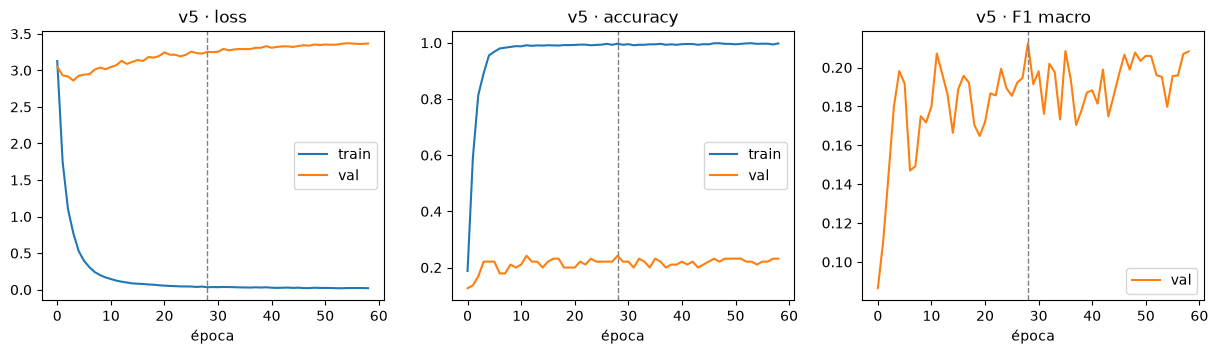

,cambio,entrada,épocas,train acc,val acc,val top5,val f1,test acc,test top5,test f1
versión,,,,,,,,,,
v5,3 recortes 384px + EfficientNetB0 (extractor) ...,651×384,59,0.997,0.242,0.6,0.212,0.242,0.516,0.242


In [13]:
keras.utils.set_random_seed(SEED)
feat_train = tf.data.Dataset.from_tensor_slices((X_train, y_train)).shuffle(len(X_train), seed=SEED).batch(BATCH_SIZE)
feat_val = tf.data.Dataset.from_tensor_slices((X_val, y_val)).batch(BATCH_SIZE)

def build_head():
    return keras.Sequential([
        keras.Input(X_train.shape[1:]),
        layers.Dropout(0.3),
        layers.Dense(NUM_CLASSES, activation="softmax"),
    ], name="clasificador")

head = build_head()

h5 = fit(head, "v5", feat_train, feat_val, epochs=300, lr=1e-3, patience=30)
plot_history(h5, "v5")

# Modelo completo: splash de 651×384 -> tres recortes -> EfficientNetB0 -> clasificador
v5 = keras.Model(extractor.input, head(extractor.output), name="v5_multirecorte")
evaluate(v5, "v5", f"3 recortes {V5_HEIGHT}px + EfficientNetB0 (extractor) + clasificador",
         h5, val_v5, test_v5, size=V5_SIZE)

## 8. v6: v5 reentrenada con train + val

Mismo modelo e hiperparámetros que la v5, entrenado con `train` + `val` (más el volteo de `val`). Sin validación para decidir cuándo parar, se usan las épocas hasta la mejor época de la v5 y el learning rate que tuvo en cada una (`LearningRateScheduler` lo repite época por época).

Épocas: 29 | learning rates: [0.0010000000474974513, 0.0005000000237487257]


Ejemplos de entrenamiento: v5 1832 → v6 2022


/Users/emiliolopez/Desktop/Septimo Semestre/lol-champion-classifier.nosync/.venv/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


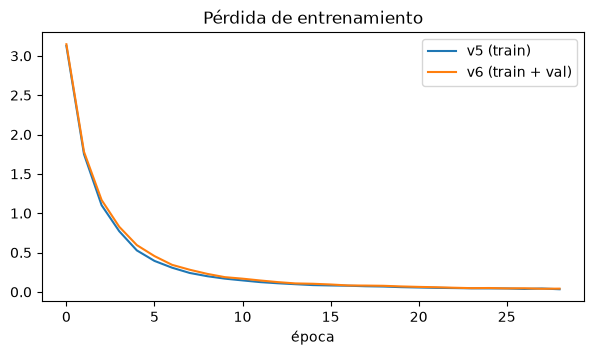

In [14]:
BEST_EPOCHS = int(np.argmax(h5.history["val_f1"])) + 1
lrs = h5.history["learning_rate"][:BEST_EPOCHS]   # learning rate de cada época de la v5
print(f"Épocas: {BEST_EPOCHS} | learning rates: {sorted(set(lrs), reverse=True)}")

X_val_flip, _ = extract(val_v5, flip=True)
X_all = np.concatenate([X_train, X_val, X_val_flip])
y_all = np.concatenate([y_train, y_val, y_val])
print(f"Ejemplos de entrenamiento: v5 {len(X_train)} -> v6 {len(X_all)}")

keras.utils.set_random_seed(SEED)
feat_all = tf.data.Dataset.from_tensor_slices((X_all, y_all)).shuffle(len(X_all), seed=SEED).batch(BATCH_SIZE)
head6 = build_head()
compile_model(head6, lrs[0])
h6 = head6.fit(feat_all, epochs=BEST_EPOCHS, verbose=0,
               callbacks=[keras.callbacks.LearningRateScheduler(lambda epoch: lrs[epoch])])

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(h5.history["loss"][:BEST_EPOCHS], label="v5 (train)")
ax.plot(h6.history["loss"], label="v6 (train + val)")
ax.set_title("Pérdida de entrenamiento"); ax.set_xlabel("época"); ax.legend()
savefig("curvas_v6")
plt.show()

In [15]:
v6 = keras.Model(extractor.input, head6(extractor.output), name="v6_train_val")
v6.save(VERSIONS_DIR / "v6.keras")
input_sizes["v6"] = V5_SIZE

t = scores(v6, test_v5)
results.append({
    "versión": "v6", "cambio": "v5 reentrenada con train + val", "entrada": f"{V5_WIDTH}x{V5_HEIGHT}",
    "épocas": BEST_EPOCHS, "train acc": h6.history["accuracy"][-1],
    "val acc": np.nan, "val top5": np.nan, "val f1": np.nan,   # val se usó para entrenar
    "test acc": t["acc"], "test top5": t["top5"], "test f1": t["f1"],
})

# Qué imágenes de test cambiaron respecto a la v5
y_test = labels_of(test_v5)
p5 = v5.predict(test_v5, verbose=0).argmax(1)
p6 = v6.predict(test_v5, verbose=0).argmax(1)
print(f"Aciertos en test: v5 {(p5 == y_test).sum()} -> v6 {(p6 == y_test).sum()} de {len(y_test)}")
print(f"Error -> acierto: {((p5 != y_test) & (p6 == y_test)).sum()} | "
      f"acierto -> error: {((p5 == y_test) & (p6 != y_test)).sum()}")
pd.DataFrame(results[-2:]).set_index("versión").round(3)

Aciertos en test: v5 23 → v6 29 de 95
Error → acierto: 8 | acierto → error: 2


,cambio,entrada,épocas,train acc,val acc,val top5,val f1,test acc,test top5,test f1
versión,,,,,,,,,,
v5,3 recortes 384px + EfficientNetB0 (extractor) ...,651×384,59,0.997,0.242,0.6,0.212,0.242,0.516,0.242
v6,v5 reentrenada con train + val,651×384,29,0.995,NaN,NaN,NaN,0.305,0.600,0.300


## 9. Diagnóstico: ¿el modelo depende del color?

Se evalúan la v5 y la v6, tal como se entrenaron, con `val` y `test` convertidos a grises. `grayscale_to_rgb` repite el canal tres veces porque EfficientNetB0 espera 3 canales.

In [16]:
def to_gray(x, y):
    return tf.image.grayscale_to_rgb(tf.image.rgb_to_grayscale(x)), y

val_gray = val_v5.map(to_gray)
test_gray = test_v5.map(to_gray)

diag = pd.DataFrame([
    {"modelo / split": name, "acc color": scores(model, ds)["acc"], "acc grises": scores(model, ds_gray)["acc"]}
    for name, model, ds, ds_gray in [("v5 / val", v5, val_v5, val_gray),
                                     ("v5 / test", v5, test_v5, test_gray),
                                     ("v6 / test", v6, test_v5, test_gray)]
]).set_index("modelo / split")
diag["aciertos color"] = (diag["acc color"] * 95).round().astype(int)
diag["aciertos grises"] = (diag["acc grises"] * 95).round().astype(int)
diag.round(3)

,acc color,acc grises,aciertos color,aciertos grises
modelo · split,,,,
v5 · val,0.242,0.284,23,27
v5 · test,0.242,0.274,23,26
v6 · test,0.305,0.337,29,32


## 10. v7: Entrenar y evaluar en escala de grises

Misma v5, cambiando solo los datos:
- **Train:** solo las copias `_bw` y su volteo. Sus características ya están en `X_train`, porque `train_v5` se cargó sin barajar; basta con filtrar sus filas.
- **Val y test:** convertidos a grises.

Características: train (916, 3840) (solo _bw), val (95, 3840) (grises)
Epoch 1/300


/Users/emiliolopez/Desktop/Septimo Semestre/lol-champion-classifier.nosync/.venv/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


29/29 - 0s - 13ms/step - accuracy: 0.0830 - loss: 3.5771 - top5: 0.2828 - val_accuracy: 0.1368 - val_loss: 3.3504 - val_top5: 0.3684 - val_f1: 0.0831 - learning_rate: 0.0010


Epoch 2/300


29/29 - 0s - 1ms/step - accuracy: 0.4138 - loss: 2.3901 - top5: 0.7238 - val_accuracy: 0.1684 - val_loss: 3.0887 - val_top5: 0.5053 - val_f1: 0.1245 - learning_rate: 0.0010


Epoch 3/300


... (114 outputs left out)

29/29 - 0s - 1ms/step - accuracy: 0.9956 - loss: 0.0269 - top5: 1.0000 - val_accuracy: 0.2947 - val_loss: 3.0175 - val_top5: 0.5579 - val_f1: 0.2694 - learning_rate: 2.5000e-04


Epoch 61/300


29/29 - 0s - 1ms/step - accuracy: 0.9978 - loss: 0.0254 - top5: 1.0000 - val_accuracy: 0.2947 - val_loss: 3.0195 - val_top5: 0.5579 - val_f1: 0.2683 - learning_rate: 2.5000e-04


v7: 3 s | mejor época 31 (val_f1 0.284)


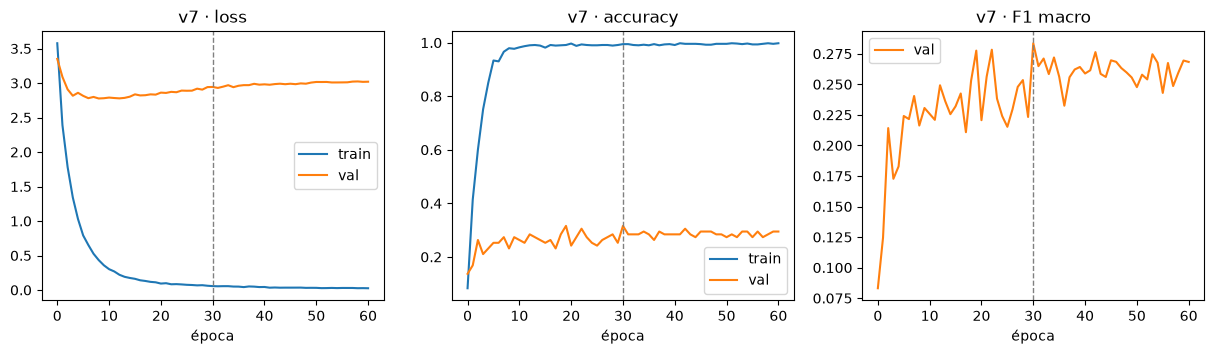

,cambio,entrada,épocas,train acc,val acc,val top5,val f1,test acc,test top5,test f1
versión,,,,,,,,,,
v7,v5 entrenada y evaluada en grises (solo _bw),651×384 grises,61,0.995,0.316,0.589,0.284,0.284,0.537,0.263


In [17]:
# Qué filas de X_train son copias _bw (X_train = originales + volteadas, en el mismo orden)
train_paths = keras.utils.image_dataset_from_directory(
    DATA_DIR / "train", class_names=CLASS_NAMES, image_size=V5_SIZE, shuffle=False, verbose=False,
).file_paths
is_bw = np.array([Path(p).stem.endswith("_bw") for p in train_paths])
is_bw = np.concatenate([is_bw, is_bw])
assert len(is_bw) == len(X_train)

X_train7, y_train7 = X_train[is_bw], y_train[is_bw]
X_val_gray, y_val_gray = extract(val_gray)
print(f"Características: train {X_train7.shape} (solo _bw), val {X_val_gray.shape} (grises)")

keras.utils.set_random_seed(SEED)
feat_train7 = tf.data.Dataset.from_tensor_slices((X_train7, y_train7)).shuffle(len(X_train7), seed=SEED).batch(BATCH_SIZE)
feat_val_gray = tf.data.Dataset.from_tensor_slices((X_val_gray, y_val_gray)).batch(BATCH_SIZE)

head7 = build_head()
h7 = fit(head7, "v7", feat_train7, feat_val_gray, epochs=300, lr=1e-3, patience=30)
plot_history(h7, "v7")

v7 = keras.Model(extractor.input, head7(extractor.output), name="v7_grises")
evaluate(v7, "v7", "v5 entrenada y evaluada en grises (solo _bw)", h7, val_gray, test_gray,
         size=V5_SIZE, gray=True)

## 11. v8: Color y grises con más peso a los grises

Se entrena con todas las imágenes de `train` (a color y `_bw`, más sus volteos), pero las de color pesan `COLOR_WEIGHT` en la pérdida (`sample_weight`). Se evalúa en grises, igual que la v7.

Ejemplos: 1832 (916 _bw con peso 1, 916 a color con peso 0.5)
Epoch 1/300


/Users/emiliolopez/Desktop/Septimo Semestre/lol-champion-classifier.nosync/.venv/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


58/58 - 0s - 7ms/step - accuracy: 0.1867 - loss: 2.3777 - top5: 0.4416 - val_accuracy: 0.0632 - val_loss: 3.1334 - val_top5: 0.4000 - val_f1: 0.0437 - learning_rate: 0.0010


Epoch 2/300


58/58 - 0s - 1ms/step - accuracy: 0.5639 - loss: 1.3573 - top5: 0.8723 - val_accuracy: 0.2211 - val_loss: 2.9125 - val_top5: 0.5474 - val_f1: 0.1808 - learning_rate: 0.0010


Epoch 3/300


... (178 outputs left out)

58/58 - 0s - 1ms/step - accuracy: 0.9978 - loss: 0.0104 - top5: 1.0000 - val_accuracy: 0.2842 - val_loss: 3.1301 - val_top5: 0.6105 - val_f1: 0.2585 - learning_rate: 3.1250e-05


Epoch 93/300


58/58 - 0s - 1ms/step - accuracy: 0.9995 - loss: 0.0103 - top5: 1.0000 - val_accuracy: 0.2842 - val_loss: 3.1328 - val_top5: 0.6105 - val_f1: 0.2585 - learning_rate: 3.1250e-05


v8: 7 s | mejor época 63 (val_f1 0.280)


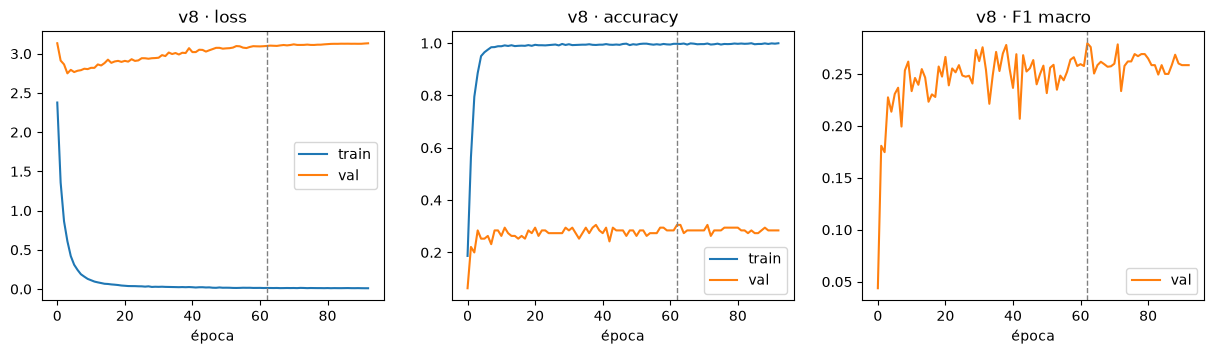

,cambio,entrada,épocas,train acc,val acc,val top5,val f1,test acc,test top5,test f1
versión,,,,,,,,,,
v8,"v5 con color (peso 0.5) + _bw, evaluada en grises",651×384 grises,93,0.997,0.305,0.611,0.28,0.295,0.537,0.277


In [18]:
COLOR_WEIGHT = 0.5
w_train8 = np.where(is_bw, 1.0, COLOR_WEIGHT)
print(f"Ejemplos: {len(X_train)} ({int(is_bw.sum())} _bw con peso 1, {int((~is_bw).sum())} a color con peso {COLOR_WEIGHT})")

keras.utils.set_random_seed(SEED)
feat_train8 = (tf.data.Dataset.from_tensor_slices((X_train, y_train, w_train8))
               .shuffle(len(X_train), seed=SEED).batch(BATCH_SIZE))

head8 = build_head()
h8 = fit(head8, "v8", feat_train8, feat_val_gray, epochs=300, lr=1e-3, patience=30)
plot_history(h8, "v8")

v8 = keras.Model(extractor.input, head8(extractor.output), name="v8_color_grises")
evaluate(v8, "v8", f"v5 con color (peso {COLOR_WEIGHT}) + _bw, evaluada en grises", h8, val_gray, test_gray,
         size=V5_SIZE, gray=True)

## 12. v9: v7 reentrenada con train + val

Igual que la v6 respecto a la v5, ahora a partir de la v7 y en grises.

In [19]:
BEST_EPOCHS7 = int(np.argmax(h7.history["val_f1"])) + 1
lrs7 = h7.history["learning_rate"][:BEST_EPOCHS7]
print(f"Épocas: {BEST_EPOCHS7} | learning rates: {sorted(set(lrs7), reverse=True)}")

X_val_gray_flip, _ = extract(val_gray, flip=True)
X_all9 = np.concatenate([X_train7, X_val_gray, X_val_gray_flip])
y_all9 = np.concatenate([y_train7, y_val_gray, y_val_gray])
print(f"Ejemplos de entrenamiento: v7 {len(X_train7)} -> v9 {len(X_all9)}")

keras.utils.set_random_seed(SEED)
feat_all9 = tf.data.Dataset.from_tensor_slices((X_all9, y_all9)).shuffle(len(X_all9), seed=SEED).batch(BATCH_SIZE)
head9 = build_head()
compile_model(head9, lrs7[0])
h9 = head9.fit(feat_all9, epochs=BEST_EPOCHS7, verbose=0,
               callbacks=[keras.callbacks.LearningRateScheduler(lambda epoch: lrs7[epoch])])

v9 = keras.Model(extractor.input, head9(extractor.output), name="v9_grises_train_val")
v9.save(VERSIONS_DIR / "v9.keras")
input_sizes["v9"] = V5_SIZE
grayscale.add("v9")

t = scores(v9, test_gray)
results.append({
    "versión": "v9", "cambio": "v7 reentrenada con train + val", "entrada": f"{V5_WIDTH}x{V5_HEIGHT} grises",
    "épocas": BEST_EPOCHS7, "train acc": h9.history["accuracy"][-1],
    "val acc": np.nan, "val top5": np.nan, "val f1": np.nan,   # val se usó para entrenar
    "test acc": t["acc"], "test top5": t["top5"], "test f1": t["f1"],
})

p7 = v7.predict(test_gray, verbose=0).argmax(1)
p9 = v9.predict(test_gray, verbose=0).argmax(1)
print(f"Aciertos en test: v7 {(p7 == y_test).sum()} -> v9 {(p9 == y_test).sum()} de {len(y_test)}")
print(f"Error -> acierto: {((p7 != y_test) & (p9 == y_test)).sum()} | "
      f"acierto -> error: {((p7 == y_test) & (p9 != y_test)).sum()}")
pd.DataFrame(results).set_index("versión").loc[["v6", "v9"]].round(3)

Épocas: 31 | learning rates: [0.0010000000474974513]


Ejemplos de entrenamiento: v7 916 → v9 1106


/Users/emiliolopez/Desktop/Septimo Semestre/lol-champion-classifier.nosync/.venv/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


Aciertos en test: v7 27 → v9 33 de 95
Error → acierto: 8 | acierto → error: 2


,cambio,entrada,épocas,train acc,val acc,val top5,val f1,test acc,test top5,test f1
versión,,,,,,,,,,
v6,v5 reentrenada con train + val,651×384,29,0.995,NaN,NaN,NaN,0.305,0.600,0.300
v9,v7 reentrenada con train + val,651×384 grises,31,0.992,NaN,NaN,NaN,0.347,0.558,0.341


## 13. Comparación de versiones

La v6 y la v9 no aparecen en la gráfica porque no tienen métricas de `val`.

In [20]:
table = pd.DataFrame(results).set_index("versión").round(3)
table

,cambio,entrada,épocas,train acc,val acc,val top5,val f1,test acc,test top5,test f1
versión,,,,,,,,,,
v1,CNN desde cero,224×224,18,1.000,0.105,0.284,0.099,0.105,0.305,0.105
v2,v1 + aumento de datos + Dropout,224×224,26,0.095,0.053,0.168,0.032,0.063,0.189,0.036
v3,EfficientNetB0 congelada + aumento,224×224,33,0.639,0.179,0.368,0.165,0.126,0.421,0.108
v4,v3 + fine-tuning desde block6a,224×224,14,0.664,0.200,0.337,0.173,0.126,0.411,0.098
v5,3 recortes 384px + EfficientNetB0 (extractor) ...,651×384,59,0.997,0.242,0.600,0.212,0.242,0.516,0.242
v6,v5 reentrenada con train + val,651×384,29,0.995,NaN,NaN,NaN,0.305,0.600,0.300
v7,v5 entrenada y evaluada en grises (solo _bw),651×384 grises,61,0.995,0.316,0.589,0.284,0.284,0.537,0.263
v8,"v5 con color (peso 0.5) + _bw, evaluada en grises",651×384 grises,93,0.997,0.305,0.611,0.280,0.295,0.537,0.277
v9,v7 reentrenada con train + val,651×384 grises,31,0.992,NaN,NaN,NaN,0.347,0.558,0.341


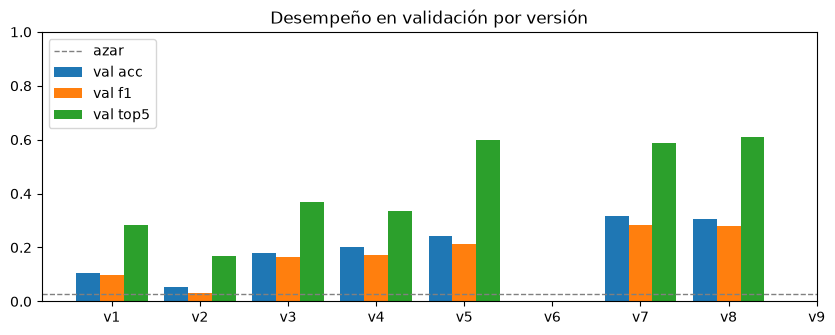

In [21]:
fig, ax = plt.subplots(figsize=(10, 3.5))
x = np.arange(len(table))
for offset, col in [(-0.27, "val acc"), (0, "val f1"), (0.27, "val top5")]:
    ax.bar(x + offset, table[col], 0.27, label=col)
ax.axhline(1 / NUM_CLASSES, color="gray", ls="--", lw=1, label="azar")
ax.set_xticks(x, table.index)
ax.set_ylim(0, 1)
ax.set_title("Desempeño en validación por versión")
ax.legend()
savefig("comparacion_versiones")
plt.show()

## 14. Análisis del modelo final en test

Se toma la versión con mejor F1 macro en `val` y se usa como modelo final su versión reentrenada con train + val.

In [22]:
best_name = table["val f1"].idxmax()   # la v6 y la v9 no tienen val f1 y no entran en la comparación
retrained = {"v5": "v6", "v7": "v9"}   # versión elegida -> la misma reentrenada con train + val
assert best_name in retrained, f"la mejor en val es {best_name}, que no tiene versión reentrenada"
final_name = retrained[best_name]
final_size = input_sizes[final_name]
final = keras.models.load_model(VERSIONS_DIR / f"{final_name}.keras")
test_ds = load_split("test", final_size)
if final_name in grayscale:
    test_ds = test_ds.map(to_gray)
print("Mejor en validación:", best_name, "| modelo final:", final_name, "| entrada:", final_size)

y_true = labels_of(test_ds)
probs = final.predict(test_ds, verbose=0)
y_pred = probs.argmax(axis=1)
top5 = np.argsort(probs, axis=1)[:, -5:]

print(f"Test accuracy: {(y_pred == y_true).mean():.3f}")
print(f"Test top-5:    {np.mean([t in row for t, row in zip(y_true, top5)]):.3f}")
print(f"Test F1 macro: {f1_score(y_true, y_pred, average='macro', zero_division=0):.3f}")

Mejor en validación: v7 | modelo final: v9 | entrada: (384, 651)


Test accuracy: 0.347
Test top-5:    0.558
Test F1 macro: 0.341


In [23]:
# Precisión, recall y F1 por campeón
report = pd.DataFrame(classification_report(
    y_true, y_pred, labels=range(NUM_CLASSES), target_names=CLASS_NAMES,
    output_dict=True, zero_division=0)).T.iloc[:NUM_CLASSES]

print("Campeones con F1 = 0 en test:", (report["f1-score"] == 0).sum(), "de", NUM_CLASSES)
print("\nMejores campeones:")
print(report.sort_values("f1-score", ascending=False).head(8).round(2).to_string())
print("\nPeores campeones:")
print(report.sort_values("f1-score").head(8).round(2).to_string())

Campeones con F1 = 0 en test: 13 de 38

Mejores campeones:
            precision  recall  f1-score  support
kaisa            0.67    1.00      0.80      2.0
annie            1.00    0.67      0.80      3.0
blitzcrank       1.00    0.67      0.80      3.0
teemo            0.67    1.00      0.80      2.0
sona             0.50    1.00      0.67      2.0
warwick          1.00    0.50      0.67      2.0
tristana         0.67    0.67      0.67      3.0
soraka           1.00    0.50      0.67      2.0

Peores campeones:
          precision  recall  f1-score  support
kayle           0.0     0.0       0.0      3.0
veigar          0.0     0.0       0.0      2.0
shaco           0.0     0.0       0.0      2.0
riven           0.0     0.0       0.0      2.0
katarina        0.0     0.0       0.0      3.0
karma           0.0     0.0       0.0      2.0
fiora           0.0     0.0       0.0      3.0
ezreal          0.0     0.0       0.0      3.0


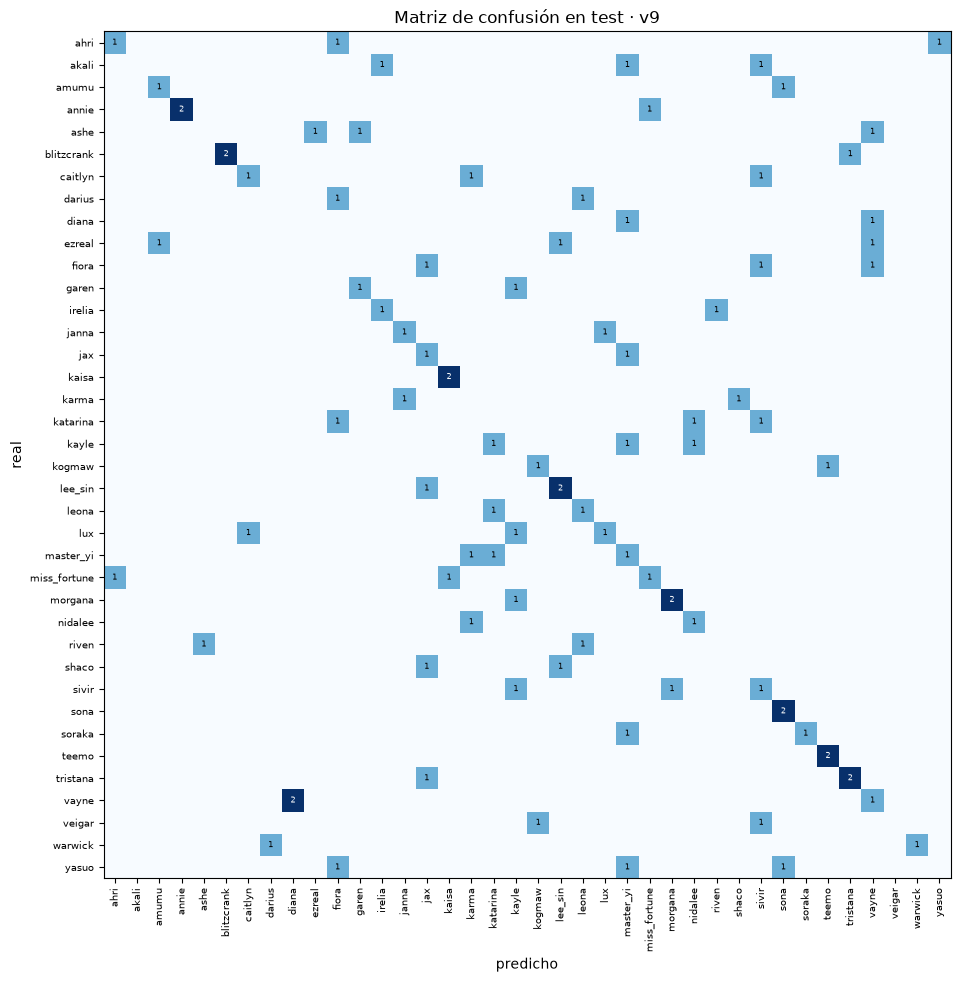

Campeones más predichos por error:
predicho
master_yi    6
sivir        5
fiora        4
vayne        4
jax          4


real   predicho    
vayne  diana           2
ahri   fiora           1
       yasuo           1
akali  master_yi       1
       irelia          1
       sivir           1
amumu  sona            1
annie  miss_fortune    1
ashe   garen           1
       vayne           1
Name: count, dtype: int64

In [24]:
cm = confusion_matrix(y_true, y_pred, labels=range(NUM_CLASSES))
fig, ax = plt.subplots(figsize=(12, 11))
ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(NUM_CLASSES), CLASS_NAMES, rotation=90, fontsize=7)
ax.set_yticks(range(NUM_CLASSES), CLASS_NAMES, fontsize=7)
ax.set_xlabel("predicho"); ax.set_ylabel("real")
ax.set_title(f"Matriz de confusión en test - {final_name}")
for i, j in zip(*np.nonzero(cm)):
    ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=6,
            color="white" if cm[i, j] > cm.max() / 2 else "black")
savefig("matriz_confusion")
plt.show()

# Errores más comunes y campeones a los que más se les asignan predicciones equivocadas
errors = pd.DataFrame({"real": [CLASS_NAMES[i] for i in y_true],
                       "predicho": [CLASS_NAMES[i] for i in y_pred]})
errors = errors[errors.real != errors.predicho]
print("Campeones más predichos por error:")
print(errors.predicho.value_counts().head(5).to_string())
errors.value_counts().head(10)

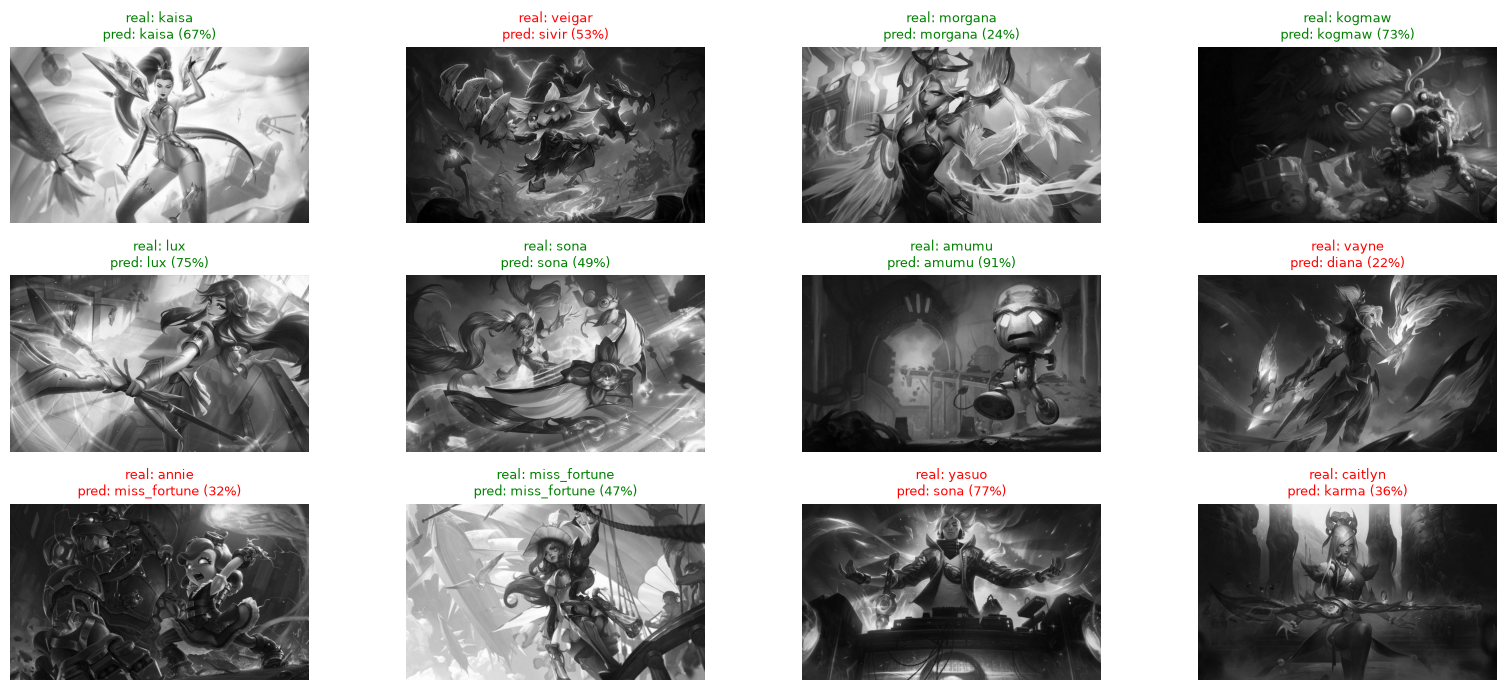

In [25]:
# Ejemplos de predicciones en test
images = np.concatenate([x.numpy() for x, _ in test_ds])
rng = np.random.default_rng(SEED)
idx = rng.choice(len(images), 12, replace=False)

fig, axes = plt.subplots(3, 4, figsize=(16, 7))
for ax, i in zip(axes.flat, idx):
    ax.imshow(images[i].astype("uint8"))
    ok = y_pred[i] == y_true[i]
    ax.set_title(f"real: {CLASS_NAMES[y_true[i]]}\npred: {CLASS_NAMES[y_pred[i]]} ({probs[i].max():.0%})",
                 fontsize=9, color="green" if ok else "red")
    ax.axis("off")
plt.tight_layout()
savefig("ejemplos_test")
plt.show()

## 15. Guardar el modelo

Se guardan el modelo (`.keras`) y `metadata.json` con las clases y el preprocesamiento que necesita `src/app.py`.

In [26]:
final.save(MODELS_DIR / "lol_champion_classifier.keras")
with open(MODELS_DIR / "metadata.json", "w") as f:
    json.dump({"class_names": CLASS_NAMES, "input_size": list(final_size),
               "resize_height": RESIZE_HEIGHT, "grayscale": final_name in grayscale,
               "version": final_name}, f, indent=1)
print("Guardado en", MODELS_DIR)

Guardado en /Users/emiliolopez/Desktop/Septimo Semestre/lol-champion-classifier.nosync/models
